# Data Cleaning & Exploratory Data Analysis (EDA) Exercise

Welcome! In this exercise, you will work with a real-world dirty dataset containing cafe sales records. Your goal is to clean the data and then perform exploratory data analysis to extract meaningful insights.

## Dataset Description
The dataset (`dirty_cafe_sales.csv`) contains information about transactions from a cafe. It includes the following columns:
- `Transaction ID`: Unique identifier for each transaction
- `Item`: Product purchased (e.g., Coffee, Cake, Cookie, Salad)
- `Quantity`: Number of units purchased
- `Price Per Unit`: Price for one unit of the item
- `Total Spent`: Total amount spent on the transaction
- `Payment Method`: How the customer paid (e.g., Credit Card, Cash, Digital Wallet)
- `Location`: Whether the order was for takeaway or in-store
- `Transaction Date`: Date of the transaction

The dataset is intentionally messy – it contains missing values, duplicates, incorrect data types, and inconsistent entries (like "ERROR" or "UNKNOWN"). Your job is to clean it up and then explore the data to find interesting patterns.

In [5]:
# Import necessary libraries
import pandas as pd
import numpy as np

# Set display options
pd.set_option('display.max_columns', None)

# Load the dataset (update the path if needed)
df = pd.read_csv("/Users/jangjiin/Desktop/Lab-8/dirty_cafe_sales.csv")

# Make a copy for safety
df_original = df.copy()

## Part 1: Initial Data Inspection

**Task 1.1** – Explore the data using the following methods:
- Display the first 10 rows
- Show a summary of the DataFrame (`.info()`)
- Generate descriptive statistics for numeric columns (`.describe()`)

*Note: Pay attention to the data types and the values that look suspicious.*

In [6]:
# Display the first 10 rows
df.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


In [7]:
#Show a summary of the DataFrame (.info()
df.info()

# Generate descriptive statistics
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


**Task 1.2** – Check for duplicate rows. How many duplicates are there? Remove them and keep the first occurrence.

In [8]:
# Your code here
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()

Number of duplicate rows: 0


**Task 1.3** – Identify missing values.
- Count missing values per column.
- Calculate the total percentage of missing values in the entire dataset.

In [9]:
# Your code here
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

percent_missing = (df.isnull().sum().sum() / df.size) * 100
print("\nPercentage of missing values:", round(percent_missing, 2), "%")

Missing values per column:
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

Percentage of missing values: 8.53 %


## Part 2: Data Cleaning

Now it's time to fix the issues you discovered.

**Task 2.1 – Handle missing values**. Decide on a strategy for each column. For example:
- Drop rows if the missing value is critical (e.g., `Transaction ID`).
- Fill numeric columns with median or mean.
- Fill categorical columns with mode or a placeholder like `'Unknown'`.

Apply your chosen strategies and verify that missing values are resolved.

Resources : https://medium.com/@heyamit10/techniques-to-pandas-impute-missing-values-993f64ad2132

In [10]:
# Your code here
df = df.dropna(subset=["Transaction ID", "Transaction Date"]).copy()

categorical_columns = ["Item", "Payment Method", "Location"]

for column in categorical_columns:
    df[column] = df[column].fillna("Unknown")

numeric_columns = ["Quantity", "Price Per Unit", "Total Spent"]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
    df[column] = df[column].fillna(df[column].median())

print(df.isnull().sum())

Transaction ID      0
Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64


**Task 2.2 – Fix incorrect data types**. Convert columns to appropriate types:
- `Quantity` should be integer
- `Price Per Unit` and `Total Spent` should be float
- `Transaction Date` should be datetime

Be careful: Some values in `Total Spent` are the string `"ERROR"`. You need to decide how to handle those (e.g., recalculate from `Quantity` and `Price Per Unit`, or drop them).

In [11]:
# Your code here
df["Quantity"] = df["Quantity"].round().astype(int)
df["Price Per Unit"] = df["Price Per Unit"].astype(float)

df["Total Spent"] = (
    df["Quantity"] * df["Price Per Unit"]
).astype(float)

df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

df = df.dropna(subset=["Transaction Date"]).copy()

df.info()

<class 'pandas.DataFrame'>
Index: 9540 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9540 non-null   str           
 1   Item              9540 non-null   str           
 2   Quantity          9540 non-null   int64         
 3   Price Per Unit    9540 non-null   float64       
 4   Total Spent       9540 non-null   float64       
 5   Payment Method    9540 non-null   str           
 6   Location          9540 non-null   str           
 7   Transaction Date  9540 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 670.8 KB


**Task 2.3 – Standardize categorical values**. For columns `Payment Method` and `Location`, replace inconsistent values like `"UNKNOWN"` with something meaningful (e.g., `'Unknown'` or the mode). You may also group rare categories if needed.

In [12]:
# Your code here
for column in ["Item", "Payment Method", "Location"]:
    df[column] = (
        df[column]
        .replace({
            "ERROR": "Unknown",
            "UNKNOWN": "Unknown"
        })
        .fillna("Unknown")
        .str.strip()
    )

print(df["Payment Method"].value_counts())
print()
print(df["Location"].value_counts())

Payment Method
Unknown           3015
Digital Wallet    2197
Credit Card       2170
Cash              2158
Name: count, dtype: int64

Location
Unknown     3779
Takeaway    2889
In-store    2872
Name: count, dtype: int64


**Task 2.4 – Create new features** (optional but useful for EDA):
- Extract `Year`, `Month`, `Day of week` from `Transaction Date`.
- If you recalculated `Total Spent`, verify that `Total Spent ≈ Quantity * Price Per Unit` (allow small rounding errors).

In [13]:
# Your code here
df["Month"] = df["Transaction Date"].dt.month
df["Day of Week"] = df["Transaction Date"].dt.day_name()

total_matches = np.isclose(
    df["Total Spent"],
    df["Quantity"] * df["Price Per Unit"]
)

print("All totals match:", total_matches.all())
df.head()

All totals match: True


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Year,Month,Day of Week
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08,2023,9,Friday
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16,2023,5,Tuesday
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19,2023,7,Wednesday
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27,2023,4,Thursday
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11,2023,6,Sunday


## Part 3: Exploratory Data Analysis (EDA)

Now that the data is clean, answer the following questions using visualizations and summary statistics.

**Task 3.1 – What are the most popular items?**
- Show the top 5 items by total quantity sold.
- Show the top 5 items by total revenue (`Total Spent`).

Top 5 items by quantity:
Item
Coffee      3425
Juice       3351
Salad       3314
Cake        3278
Sandwich    3266
Name: Quantity, dtype: int64

Top 5 items by revenue:
Item
Salad       16198.0
Sandwich    12892.0
Smoothie    12643.0
Juice       10053.0
Cake         9834.0
Name: Total Spent, dtype: float64


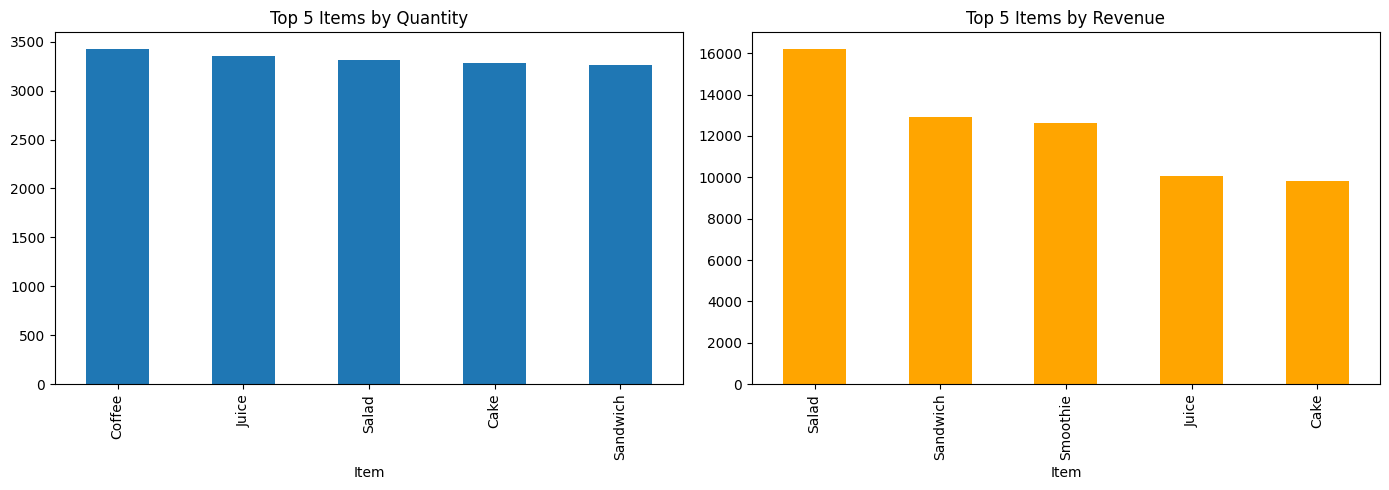

In [14]:
# Your code here
import matplotlib.pyplot as plt

known_items = df[df["Item"] != "Unknown"]

# Top 5 items by quantity
top_quantity = (
    known_items.groupby("Item")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_revenue = (
    known_items.groupby("Item")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 items by quantity:")
print(top_quantity)

print("\nTop 5 items by revenue:")
print(top_revenue)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_quantity.plot(
    kind="bar",
    ax=axes[0],
    title="Top 5 Items by Quantity"
)

top_revenue.plot(
    kind="bar",
    ax=axes[1],
    title="Top 5 Items by Revenue",
    color="orange"
)

plt.tight_layout()
plt.show()

**Task 3.2 – Sales by payment method and location**
- Calculate total revenue per payment method. Which method brings the most income?
- Calculate total revenue for `In-store` vs `Takeaway`. Does one dominate?

Revenue by payment method:
Payment Method
Digital Wallet    19703.0
Cash              19621.0
Credit Card       19476.5
Name: Total Spent, dtype: float64

Highest revenue payment method: Digital Wallet

Revenue by location:
Location
In-store    25906.5
Takeaway    25521.5
Name: Total Spent, dtype: float64

Highest revenue location: In-store


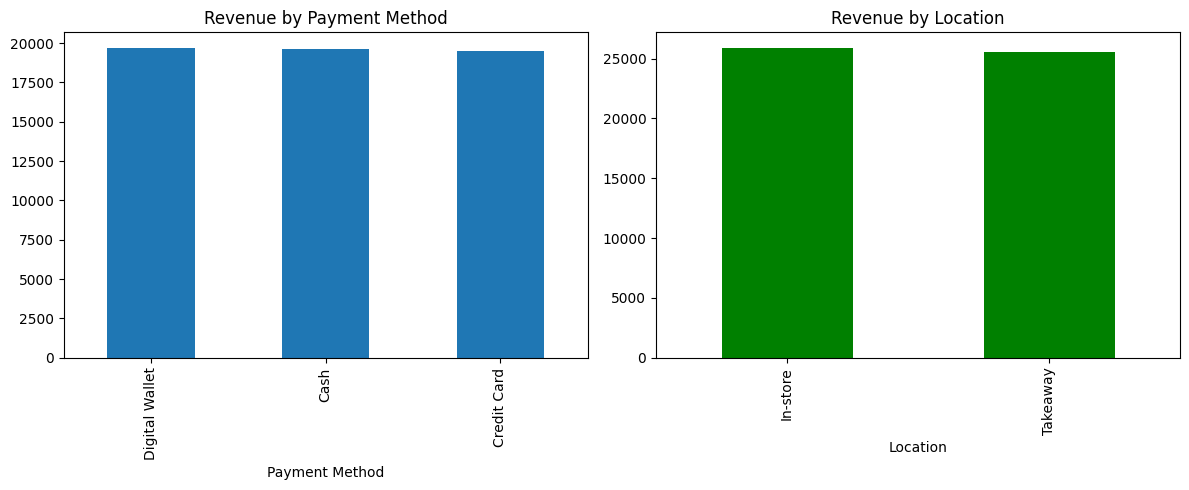

In [15]:
# Your code here
payment_revenue = (
    df[df["Payment Method"] != "Unknown"]
    .groupby("Payment Method")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

location_revenue = (
    df[df["Location"].isin(["In-store", "Takeaway"])]
    .groupby("Location")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by payment method:")
print(payment_revenue)
print("\nHighest revenue payment method:", payment_revenue.idxmax())

print("\nRevenue by location:")
print(location_revenue)
print("\nHighest revenue location:", location_revenue.idxmax())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

payment_revenue.plot(
    kind="bar",
    ax=axes[0],
    title="Revenue by Payment Method"
)

location_revenue.plot(
    kind="bar",
    ax=axes[1],
    title="Revenue by Location",
    color="green"
)

plt.tight_layout()
plt.show()

**Task 3.3 – Time trends**
- Identify the day of week with highest average sales.
- Is there any month with unusually low sales?

Average sales by day of week:
Day of Week
Tuesday      9.184211
Sunday       9.008696
Thursday     8.981159
Friday       8.896614
Saturday     8.866348
Monday       8.830318
Wednesday    8.790082
Name: Total Spent, dtype: float64

Highest average sales day: Tuesday

Total sales by month:
Month
1     7258.0
2     6673.0
3     7215.5
4     7193.5
5     6978.5
6     7417.5
7     6927.5
8     7101.0
9     6886.0
10    7353.5
11    7021.0
12    7221.5
Name: Total Spent, dtype: float64

Month with the lowest sales: 2


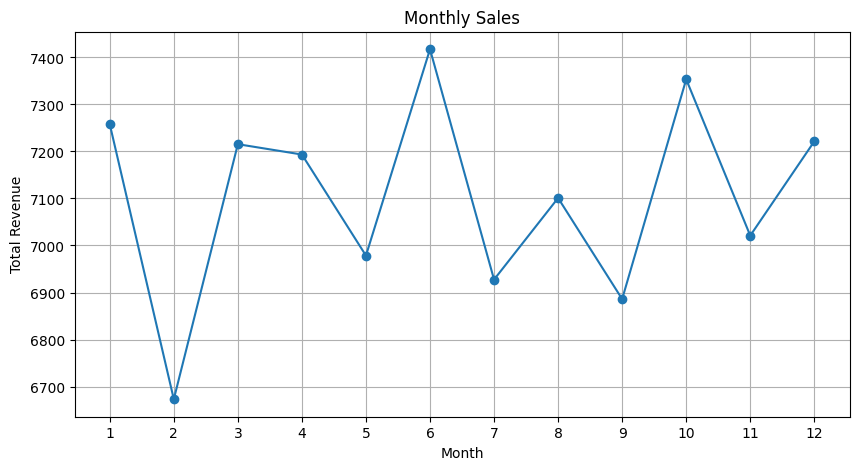

In [16]:
# Your code here
daily_average = (
    df.groupby("Day of Week")["Total Spent"]
    .mean()
    .sort_values(ascending=False)
)

monthly_sales = (
    df.groupby("Month")["Total Spent"]
    .sum()
    .sort_index()
)

print("Average sales by day of week:")
print(daily_average)
print("\nHighest average sales day:", daily_average.idxmax())

print("\nTotal sales by month:")
print(monthly_sales)
print("\nMonth with the lowest sales:", monthly_sales.idxmin())

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Sales"
)

plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

**Task 3.4 – Outlier detection**
- Use a boxplot to check if `Quantity` or `Total Spent` contain extreme outliers.
- If outliers exist, decide whether to keep, cap, or remove them (explain your reasoning).

Learning Resource : https://www.kaggle.com/code/rpsuraj/outlier-detection-techniques-simplified

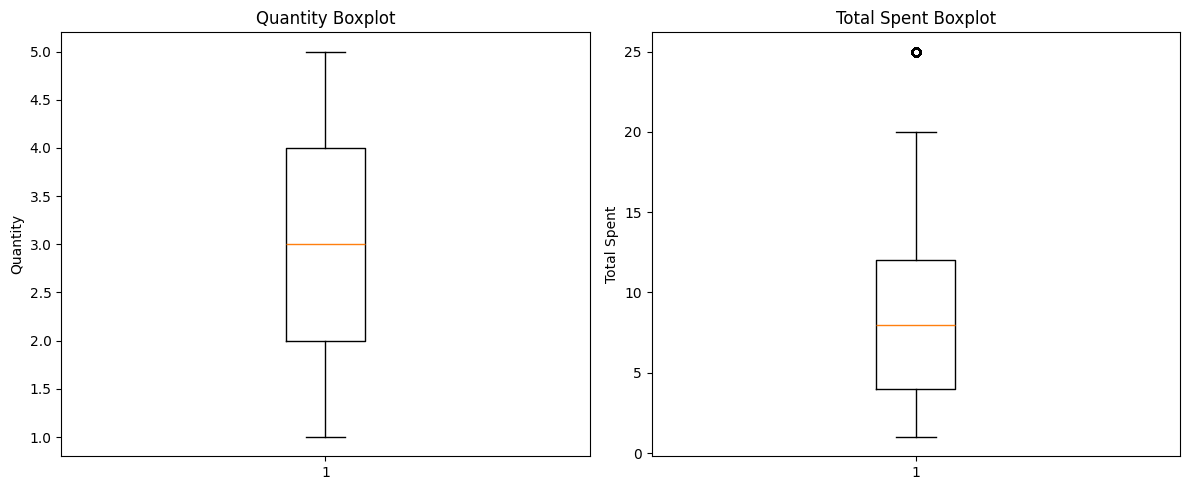

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df["Quantity"].dropna())
axes[0].set_title("Quantity Boxplot")
axes[0].set_ylabel("Quantity")

axes[1].boxplot(df["Total Spent"].dropna())
axes[1].set_title("Total Spent Boxplot")
axes[1].set_ylabel("Total Spent")

plt.tight_layout()
plt.show()

# The possible outliers are kept because the values are
# valid based on the quantity and price ranges.

**Task 3.5 – Correlation analysis**
- Compute the correlation matrix between numeric columns (e.g., `Quantity`, `Price Per Unit`, `Total Spent`).
- What relationships stand out?

                Quantity  Price Per Unit  Total Spent
Quantity        1.000000        0.003769     0.706807
Price Per Unit  0.003769        1.000000     0.645144
Total Spent     0.706807        0.645144     1.000000


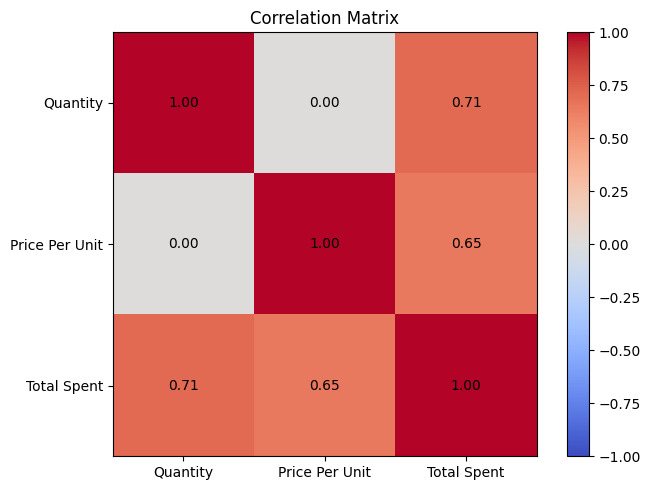

In [23]:
# Your code here
correlation_matrix = df[
    ["Quantity", "Price Per Unit", "Total Spent"]
].corr()

print(correlation_matrix)

print("\nTotal Spent has a strong positive relationship with")
print("both Quantity and Price Per Unit.")

## Part 4: Summary & Insights

**Task 4.1** – Write a short summary (3-5 bullet points) of the most interesting findings from your analysis. Include at least one actionable business recommendation based on the data.

- Coffee was the most popular known item by quantity.
- Salad generated the highest revenue among known items.
- Digital Wallet generated the most revenue among known payment methods, and In-store revenue was slightly higher than Takeaway revenue.
- Tuesday had the highest average sales, while February had the lowest monthly sales.
- Business recommendation: Promote high-revenue items such as Salad and Sandwich, and improve the collection of payment method and location data.